In [35]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sys
import os
from rna_utils import compute_bpp_scores

In [36]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 16
    }
)

In [37]:
fname_data = "../Group_I_Intron/Matching_Data.csv"
df_raw = pd.read_csv(fname_data)
df_raw.head()

,names,activities_lowT,activities_highT,distances,sequences,DCA,SB
0,dca_f_mutations_129,-1.316208,-2.724580,55,GUGCCUUUCGACAGGAAACUUCGAAAGGAAUCCUGUCAAAUUCGGC...,37.074856,6.852815
1,dca_f_mutations_261,-2.664200,-999.000000,60,GUGCACUUUGUCGGGUUGCCGCAGAGUGAAUGUGGUCAAAUUCAAG...,33.076924,4.896689
2,dca_f_mutations_7,-2.736124,-999.000000,55,GUGCACUCAGCCGGGAAGCCGCAUAGUGGAUGUUCUCAAAUUCGGU...,28.189787,5.859439
3,dca_f_sequenza_1,-0.048592,1.969441,5,GUGCCUUUCGCCGGGAAACCACGAAAGGGAUGGUGUCAAAUUCGGC...,0.570879,5.453645
4,dca_f_sequenza_10,0.261965,1.722767,5,GUGCCUUGCGCCGGGAAACCACGCAAGGGAUGGUGUCAAAUUCGGC...,-0.357110,5.515907


In [38]:
df = df_raw.filter(["names", "activities_lowT", "activities_highT", "distances", "sequences"])
df.head()

,names,activities_lowT,activities_highT,distances,sequences
0,dca_f_mutations_129,-1.316208,-2.724580,55,GUGCCUUUCGACAGGAAACUUCGAAAGGAAUCCUGUCAAAUUCGGC...
1,dca_f_mutations_261,-2.664200,-999.000000,60,GUGCACUUUGUCGGGUUGCCGCAGAGUGAAUGUGGUCAAAUUCAAG...
2,dca_f_mutations_7,-2.736124,-999.000000,55,GUGCACUCAGCCGGGAAGCCGCAUAGUGGAUGUUCUCAAAUUCGGU...
3,dca_f_sequenza_1,-0.048592,1.969441,5,GUGCCUUUCGCCGGGAAACCACGAAAGGGAUGGUGUCAAAUUCGGC...
4,dca_f_sequenza_10,0.261965,1.722767,5,GUGCCUUGCGCCGGGAAACCACGCAAGGGAUGGUGUCAAAUUCGGC...


In [39]:
fname_structure = "../Group_I_Intron/dot-bracket-structure.txt"
with open(fname_structure, "r") as f:
    structure = f.read().strip()

In [40]:
sb_scores = compute_bpp_scores(df["sequences"].tolist(), structure, 10)
df["sb_scores"] = sb_scores
df.head()

,names,activities_lowT,activities_highT,distances,sequences,sb_scores
0,dca_f_mutations_129,-1.316208,-2.724580,55,GUGCCUUUCGACAGGAAACUUCGAAAGGAAUCCUGUCAAAUUCGGC...,19.306218
1,dca_f_mutations_261,-2.664200,-999.000000,60,GUGCACUUUGUCGGGUUGCCGCAGAGUGAAUGUGGUCAAAUUCAAG...,40.572451
2,dca_f_mutations_7,-2.736124,-999.000000,55,GUGCACUCAGCCGGGAAGCCGCAUAGUGGAUGUUCUCAAAUUCGGU...,28.339085
3,dca_f_sequenza_1,-0.048592,1.969441,5,GUGCCUUUCGCCGGGAAACCACGAAAGGGAUGGUGUCAAAUUCGGC...,28.241765
4,dca_f_sequenza_10,0.261965,1.722767,5,GUGCCUUGCGCCGGGAAACCACGCAAGGGAUGGUGUCAAAUUCGGC...,38.127976


In [41]:
import torch
device = torch.device("mps")  # Use "cuda" if you have a compatible GPU, otherwise use "cpu"
dtype = torch.float32

tokens = "ACGU-"
path_model = "../modello_FC_T=1"
params_file = np.load(path_model, allow_pickle=True)

params = {
    "bias": torch.tensor(params_file["h_local"], dtype=dtype, device=device).contiguous(),
    "coupling_matrix": torch.tensor(params_file["couplings"], dtype=dtype, device=device),
}

In [42]:
import adabmDCA as abm
seqs_enc = abm.encode_sequence(df["sequences"].tolist(), tokens)[:, 3:-1]
seqs_pt = torch.tensor(seqs_enc, dtype=torch.long, device=device)
seqs_pt = torch.nn.functional.one_hot(seqs_pt, num_classes=len(tokens)).float()

energies = abm.compute_energy(seqs_pt, params).cpu().numpy()
df["dca_scores"] = energies

In [43]:
df.to_csv("../Group_I_Intron/Matching_Data_corrected.csv", index=False)

In [55]:
activity_th_lowT = -2.76
activity_th_highT = -2.0
min_distance_azo, max_distance_azo = 25, 30
models_filter = ["dca_f", "old_dca"]

mask1 = df["distances"].between(min_distance_azo, max_distance_azo)
mask2a = [models_filter[0] in name for name in df["names"]]
mask2b = [models_filter[1] in name for name in df["names"]]
mask2 = np.logical_or(mask2a, mask2b)
mask3 = df["activities_lowT"] > activity_th_lowT
mask_global = np.logical_and.reduce([mask1, mask2, mask3])
df_filtered = df.loc[mask_global].copy()
df_filtered["active_highT"] = df_filtered["activities_highT"] > activity_th_highT
df_filtered.reset_index(inplace=True, drop=True)

df_filtered.describe()

,activities_lowT,activities_highT,distances,sb_scores,dca_scores
count,317.000000,317.000000,317.000000,317.000000,317.000000
mean,-1.021352,-228.096964,27.634069,29.646708,79.851807
std,0.736905,418.572193,2.075743,6.294359,3.806240
min,-2.756148,-999.000000,25.000000,1.304527,67.966293
25%,-1.601213,-3.931826,25.000000,26.066301,77.592224
50%,-0.737247,-1.897120,28.000000,31.091351,80.125488
75%,-0.384807,-0.860201,30.000000,34.594208,82.599457
max,0.072312,0.621688,30.000000,39.618370,92.107117


In [56]:
df_filtered

,names,activities_lowT,activities_highT,distances,sequences,sb_scores,dca_scores,active_highT
0,dca_f_sequenza_601,-1.347339,-3.555348,25,GUGCCUUGCGCUGGGAAUCCACGUAAGUGAUGGUGUCAAAUUCGGU...,37.269312,81.517044,False
1,dca_f_sequenza_603,-1.079397,-3.367296,25,GUGCGUUACACCGGGAAUCCGCGUAAGGGAUGGUGUCAAAUUCGGA...,17.977436,82.021637,False
2,dca_f_sequenza_604,-0.388843,-3.218876,25,GUGCCUCUCGCAGGGAAACCUCGGAAGGGAUGGUGUCAAAUUCGGU...,36.647701,83.089249,False
3,dca_f_sequenza_605,-0.695655,-999.000000,25,GUGAAUUCCGCAGGGAAACCGCGGAAUGGACGGUGUCAAAUUCAGA...,30.437034,80.851807,False
4,dca_f_sequenza_609,-2.756148,-999.000000,25,GUGCCGUGCGCCGGGAAGCCGCGUAAGGGAUGGUGUCAAAUUCGGU...,22.511049,79.138351,False
...,...,...,...,...,...,...,...,...
312,old_dca_953_30_40,-1.874644,-999.000000,30,GUGUCGUGCGGCGGGAAACCGUGUAAGGGAUGCUGUCAAAUUCGGU...,22.258691,82.275284,False
313,old_dca_955_30_40,-0.452952,-0.133531,30,GUGCCGUGCAGCGGGAAACCGUGUAAGGGAUGGUGUCAAAUUCGGU...,34.867282,78.573242,True
314,old_dca_958_30_40,-0.571766,-2.944439,30,GUGCCGUGCGGCGGGAAACUGUGUAAGGGAUGGUGUCAAAUUCGGU...,31.035844,83.835846,False
315,old_dca_975_30_40,-0.230741,-0.600774,30,GUGCCUUGCAGCGGGAAACCGUGUAAGGGAUGGUGUCAAAUUCGGU...,35.601751,75.548172,True


<>:51: SyntaxWarning: invalid escape sequence '\%'
<>:52: SyntaxWarning: invalid escape sequence '\%'
<>:51: SyntaxWarning: invalid escape sequence '\%'
<>:52: SyntaxWarning: invalid escape sequence '\%'
/var/folders/r7/6v5_mzt97glb0kxr73vgmbs00000gn/T/ipykernel_1956/3876363421.py:51: SyntaxWarning: invalid escape sequence '\%'
  above_text = f"Active fraction: {pct_active_above:.1f}\%"
/var/folders/r7/6v5_mzt97glb0kxr73vgmbs00000gn/T/ipykernel_1956/3876363421.py:52: SyntaxWarning: invalid escape sequence '\%'
  below_text = f"Active fraction: {pct_active_below:.1f}\%"


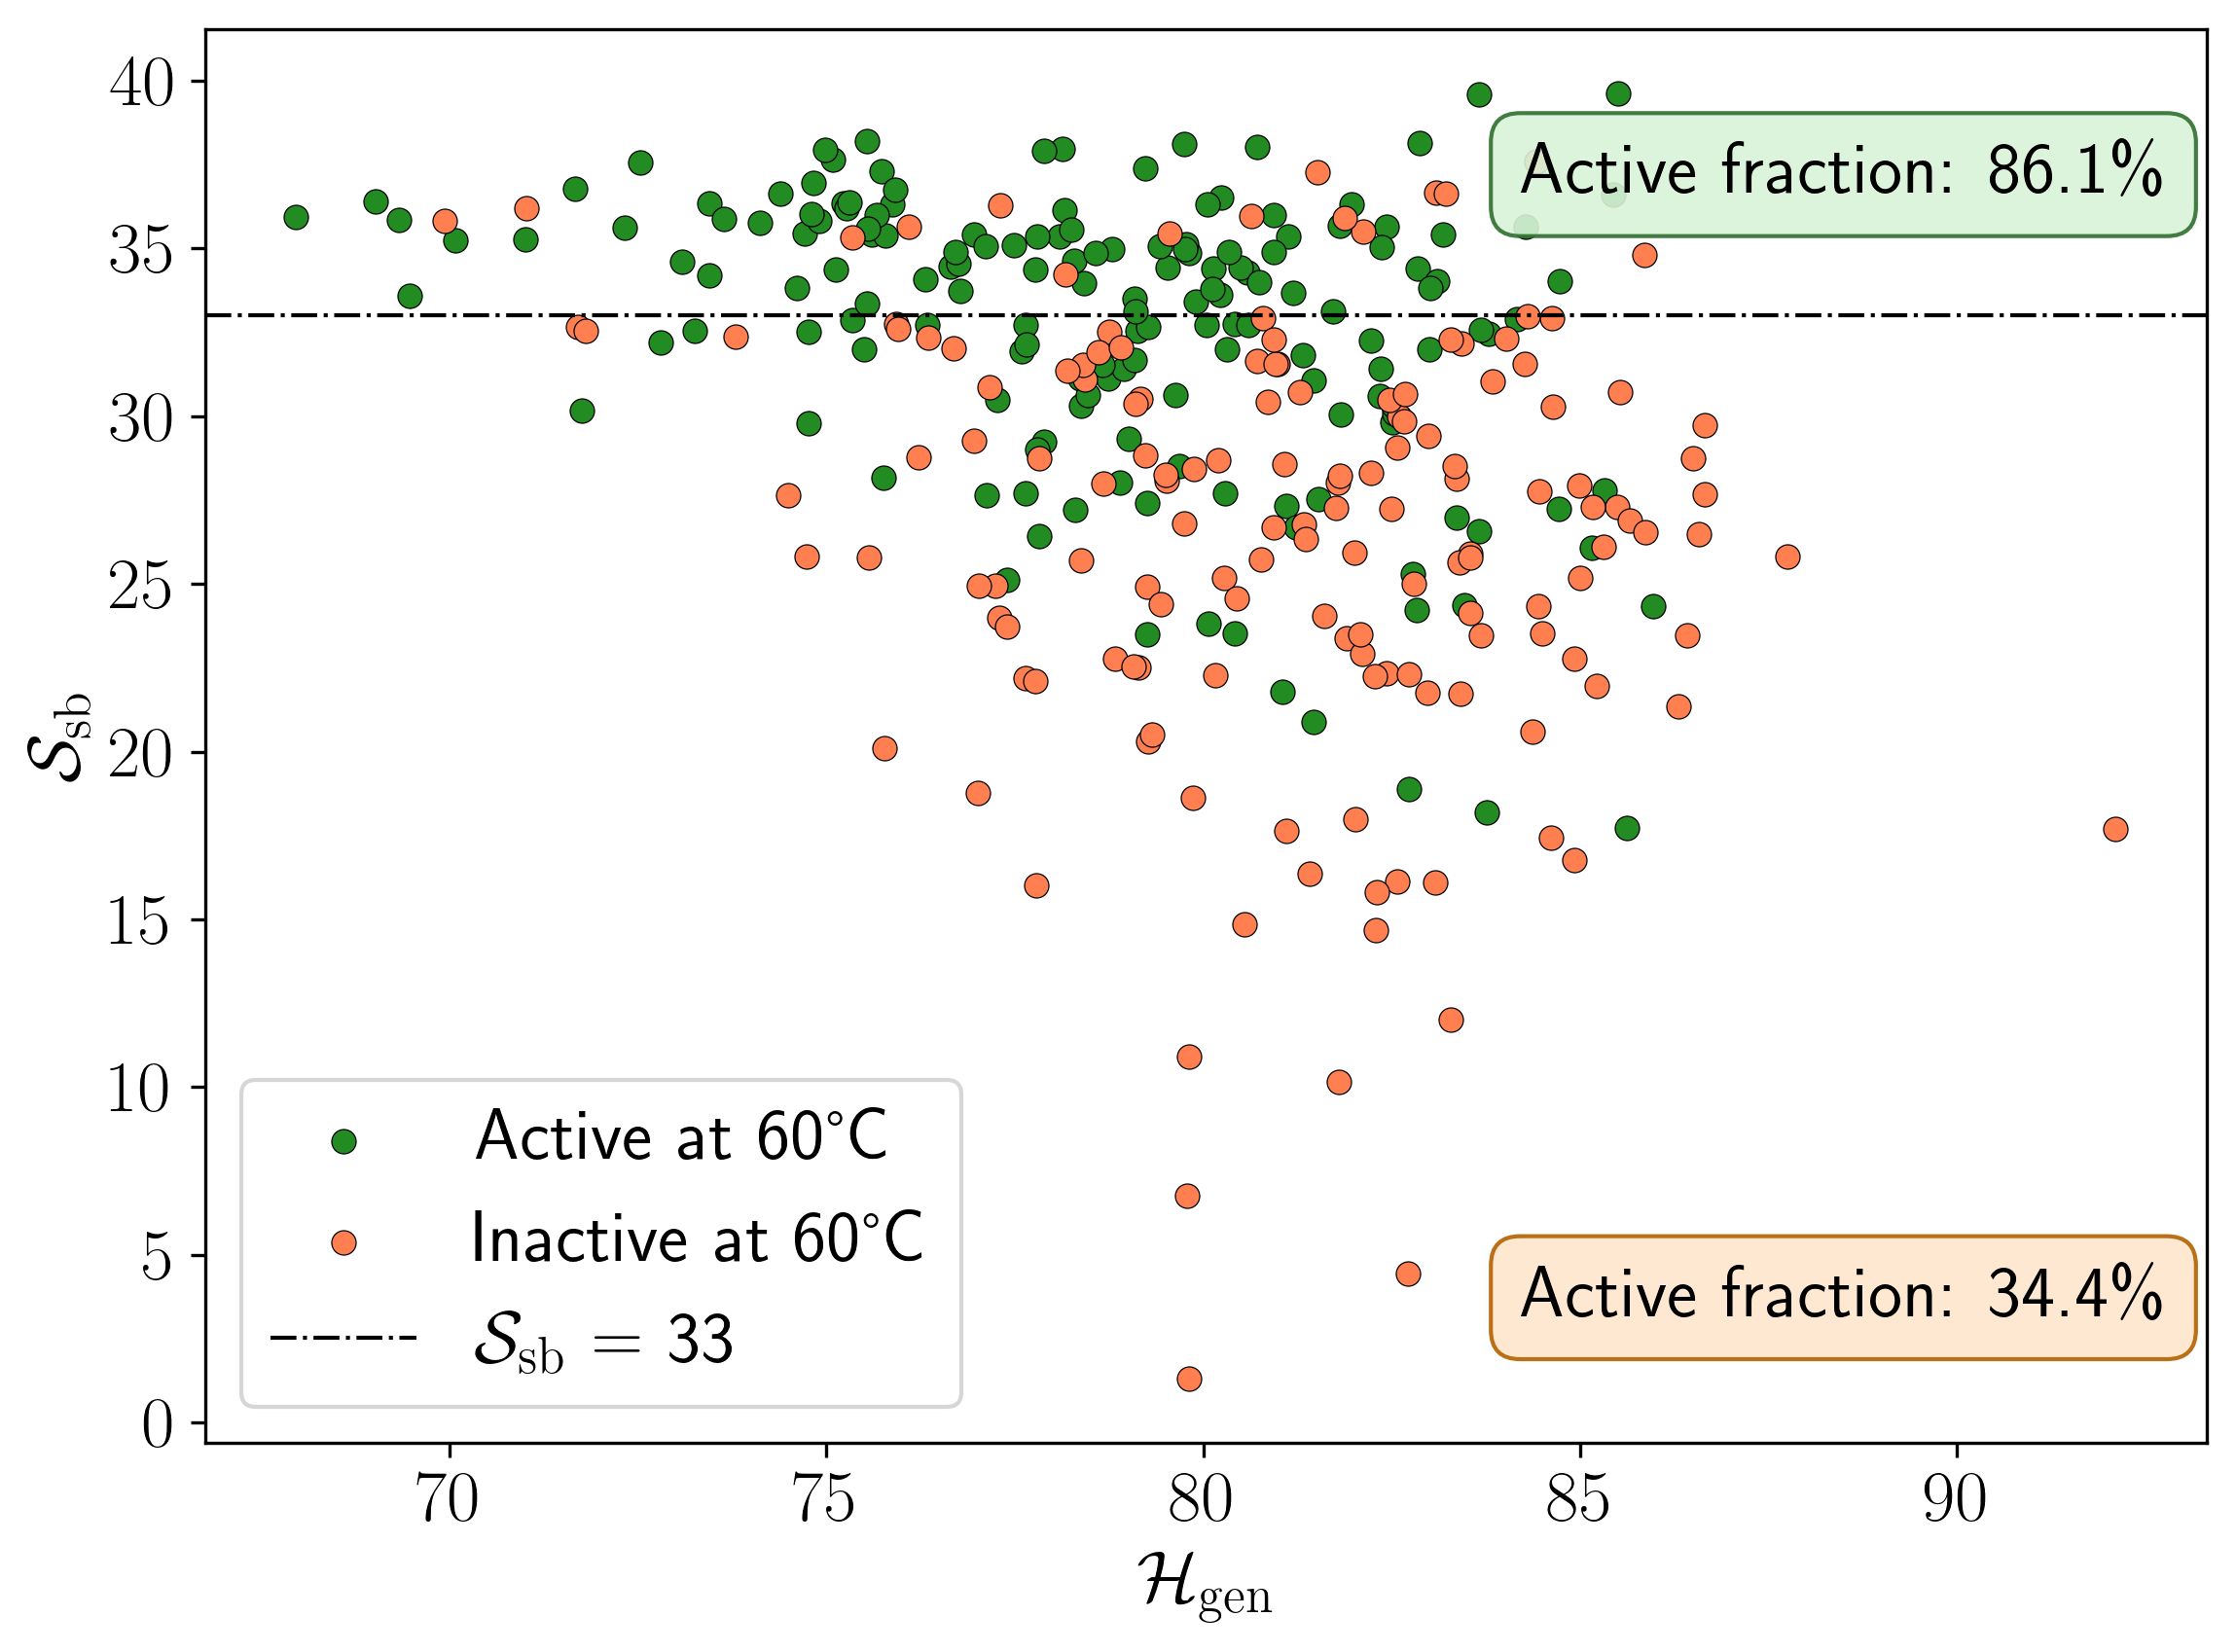

In [71]:
plt.rcParams.update(
    {
        "font.size": 18
    }
)

sb_threshold = 33

# Work on filtered data if present; otherwise fall back to full df.
plot_df = df_filtered.copy() if "df_filtered" in globals() else df.copy()

# Boolean mask for active/inactive points.
active_mask = plot_df["active_highT"] == True

# Percentages of active sequences above/below the SB threshold.
active_above = ((plot_df["sb_scores"] > sb_threshold) & active_mask).sum()
active_below = ((plot_df["sb_scores"] <= sb_threshold) & active_mask).sum()
total_above = (plot_df["sb_scores"] > sb_threshold).sum()
total_below = (plot_df["sb_scores"] <= sb_threshold).sum()

pct_active_above = (100 * active_above / total_above) if total_above > 0 else 0.0
pct_active_below = (100 * active_below / total_below) if total_below > 0 else 0.0

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Scatter points by activity class.
ax.scatter(
    plot_df.loc[active_mask, "dca_scores"],
    plot_df.loc[active_mask, "sb_scores"],
    c="forestgreen",
    label="Active at 60°C",
    alpha=1.0,
    edgecolors="k",
    linewidths=0.3,
)
ax.scatter(
    plot_df.loc[~active_mask, "dca_scores"],
    plot_df.loc[~active_mask, "sb_scores"],
    c="coral",
    label="Inactive at 60°C",
    alpha=1.0,
    edgecolors="k",
    linewidths=0.3,
)

# Horizontal threshold line.
ax.axhline(sb_threshold, color="black", linestyle="-.", linewidth=1.0, label=r"$\mathcal{S}_\mathrm{sb}$" + f" = {sb_threshold}")
ax.legend()

# Add two annotation boxes on the right side: one above and one below the threshold.
above_text = f"Active fraction: {pct_active_above:.1f}\%"
below_text = f"Active fraction: {pct_active_below:.1f}\%"

ax.text(
    0.98,
    0.92,
    above_text,
    transform=ax.transAxes,
    va="top",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#d9f2d9", edgecolor="#2f6f2f", alpha=0.9),
)
ax.text(
    0.98,
    0.08,
    below_text,
    transform=ax.transAxes,
    va="bottom",
    ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#ffe6cc", edgecolor="#b36200", alpha=0.9),
)

ax.set_xlabel(r"$\mathcal{H}_\mathrm{gen}$")
ax.set_ylabel(r"$\mathcal{S}_\mathrm{sb}$")

plt.tight_layout()
plt.savefig("../../../results/Images/Group_I_intron/active_fractions_old_data.pdf")
plt.savefig("../../../results/Images/Group_I_intron/active_fractions_old_data.png")
plt.show()